# анализ данных


In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv("Titanic-Dataset.csv", index_col="PassengerId")
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.shape

(891, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


In [ ]:
df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_table = pd.DataFrame({"пропусков": missing, "%": missing_pct})
print(missing_table[missing_table["пропусков"] > 0])

          пропусков     %
Age             177  19.9
Cabin           687  77.1
Embarked          2   0.2


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

полных дубликатов: 0
Survived
0    549
1    342
Name: count, dtype: int64

доля выживших: 38.4%


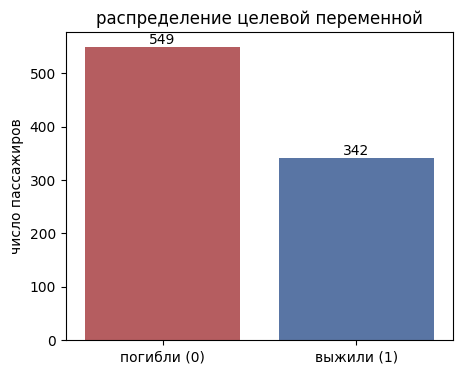

In [ ]:
print("полных дубликатов:", df.duplicated().sum())

counts = df["Survived"].value_counts()
print(counts)
print(f"\nдоля выживших: {counts[1] / len(df) * 100:.1f}%")

plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Survived", data=df, hue="Survived",
                   palette=["#c44e52", "#4c72b0"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["погибли (0)", "выжили (1)"])
ax.set_title("распределение целевой переменной")
ax.set_xlabel("")
ax.set_ylabel("число пассажиров")
for c in ax.containers:
    ax.bar_label(c)
plt.show()

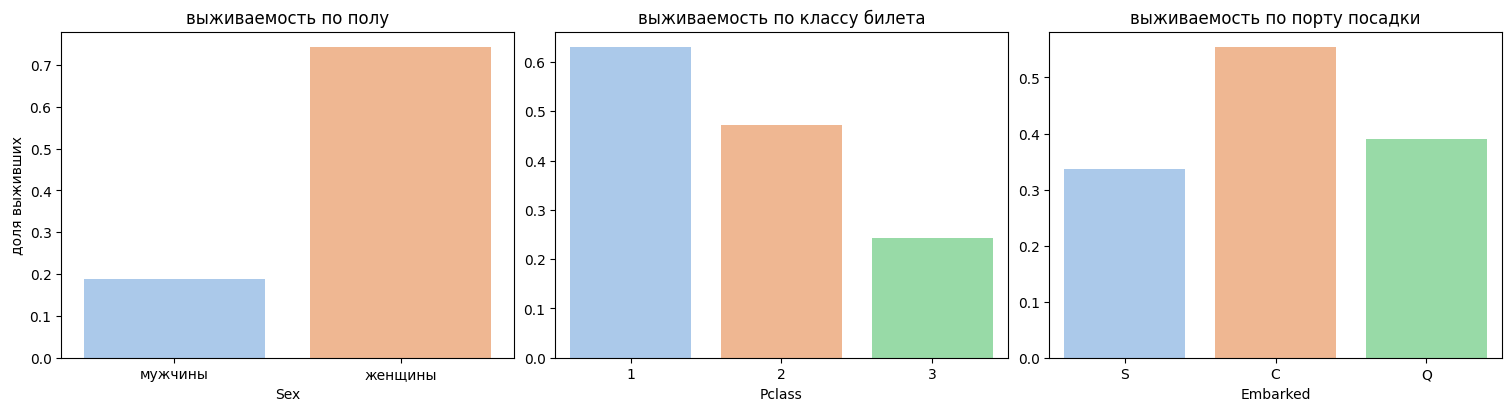


Sex (% выживших | человек в группе)
        mean  count
Sex                
female  74.2    314
male    18.9    577

Pclass (% выживших | человек в группе)
        mean  count
Pclass             
1       63.0    216
2       47.3    184
3       24.2    491

Embarked (% выживших | человек в группе)
          mean  count
Embarked             
C         55.4    168
Q         39.0     77
S         33.7    644


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

sns.barplot(x="Sex", y="Survived", data=df, ax=axes[0], hue="Sex",
            palette="pastel", legend=False, errorbar=None)
axes[0].set_title("выживаемость по полу")
axes[0].set_ylabel("доля выживших")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["мужчины", "женщины"])

sns.barplot(x="Pclass", y="Survived", data=df, ax=axes[1], hue="Pclass",
            palette="pastel", legend=False, errorbar=None)
axes[1].set_title("выживаемость по классу билета")
axes[1].set_ylabel("")

sns.barplot(x="Embarked", y="Survived", data=df, ax=axes[2], hue="Embarked",
            palette="pastel", legend=False, errorbar=None)
axes[2].set_title("выживаемость по порту посадки")
axes[2].set_ylabel("")

plt.show()

for col in ["Sex", "Pclass", "Embarked"]:
    grp = df.groupby(col)["Survived"].agg(["mean", "count"])
    grp["mean"] = (grp["mean"] * 100).round(1)
    print(f"\n{col} (% выживших | человек в группе)")
    print(grp)

данные не сбалансированы поэтому основная метрика это F1 среднее гарманическое чтобы была справедливая оценка

Age — 177 (19.9%): признак ценный заполним медианой;
Cabin — 687 (77.1%): данных слишком мало колонку удаляем;
Embarked — 2 (0.2%): заполним модой

PassengerId, Name, Ticket — уникальныеидентификаторы конкретных людей модель просто выучит их а не найдет закономерность удалим эти столбцы

пол — сильнейший признак: выжили 74.2% женщин против 18.9% мужчин;
класс билета сильно связан с выживанием: 1-й класс 63.0%, 2-й 47.3%, 3-й 24.2%

In [ ]:
df.head(5)

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# обработка данных

In [ ]:
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

df['Title'] = df['Title'].replace(['Lady', 'Countess','Capt', 'Col',\
 	'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')

df['Title'] = df['Title'].replace('Mlle', 'Miss')
df['Title'] = df['Title'].replace('Ms', 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')

<>:1: SyntaxWarning: invalid escape sequence '\.'
<>:1: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_1001/1903057653.py:1: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


In [ ]:
df.drop(columns=["Cabin", 'Name', 'Ticket'], inplace=True)

In [ ]:
from sklearn.impute import SimpleImputer, KNNImputer

imputer = SimpleImputer(missing_values=pd.NA, strategy='most_frequent')

df[['Embarked']] = imputer.fit_transform(df[['Embarked']])

numimp = KNNImputer(missing_values=np.nan, n_neighbors=5)

df[['Age']] = numimp.fit_transform(df[['Age']])

In [ ]:
df.isna().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0
Title,0


In [ ]:
categorical_columns = ['Pclass', 'Sex', 'SibSp', 'Parch','Embarked', 'Title']

categorical_features = df[categorical_columns]

categorical_features.columns

unprocessed_cat_features = categorical_features.select_dtypes(include=[object]).columns.tolist()
df[unprocessed_cat_features]

,Sex,Embarked,Title
PassengerId,,,
1,male,S,Mr
2,female,C,Mrs
3,female,S,Miss
4,female,S,Mrs
5,male,S,Mr
...,...,...,...
887,male,S,Rare
888,female,S,Miss
889,female,S,Miss


In [ ]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False)

encoded = ohe.fit_transform(df[unprocessed_cat_features])
newdata = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(unprocessed_cat_features), index=df.index)

newdata

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
PassengerId,,,,,,,,,,
1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
887,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
888,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
889,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
ohdata = pd.concat([df, newdata], axis=1)

ohdata.drop(unprocessed_cat_features, axis=1, inplace=True)

ohdata

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
PassengerId,,,,,,,,,,,,,,,,
1,0,3,22.000000,1,0,7.2500,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,1,1,38.000000,1,0,71.2833,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,3,26.000000,0,0,7.9250,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1,1,35.000000,1,0,53.1000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5,0,3,35.000000,0,0,8.0500,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,0,2,27.000000,0,0,13.0000,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
888,1,1,19.000000,0,0,30.0000,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
889,0,3,29.699118,1,2,23.4500,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
ohdata['Fare'] = np.log1p(ohdata['Fare']) # ln(x + 1)

In [ ]:
ohdata.isna().sum()

,0
Survived,0
Pclass,0
Age,0
SibSp,0
Parch,0
Fare,0
Sex_female,0
Sex_male,0
Embarked_C,0
Embarked_Q,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
x = ohdata.drop(columns=['Survived'])
y = ohdata['Survived']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
scaler = StandardScaler()
scaler.fit(x_train)

X_train_scaled = pd.DataFrame(scaler.transform(x_train), columns=x_train.columns, index=x_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(x_test),  columns=x_test.columns,  index=x_test.index)

# Dummy baseline

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, classification_report)

In [ ]:
dummy = DummyClassifier(strategy="most_frequent", random_state=42)
dummy.fit(x_train, y_train)

DummyClassifier(random_state=42, strategy='most_frequent')

In [ ]:
y_pred_dummy = dummy.predict(X_test_scaled)

pd.Series(y_pred_dummy).value_counts()

,count
0,179


In [ ]:
acc_dummy  = accuracy_score(y_test, y_pred_dummy)
prec_dummy = precision_score(y_test, y_pred_dummy, zero_division=0)
rec_dummy  = recall_score(y_test, y_pred_dummy, zero_division=0)
f1_dummy   = f1_score(y_test, y_pred_dummy, zero_division=0)

metrics_dummy = pd.DataFrame({
    "метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "значение": [acc_dummy, prec_dummy, rec_dummy, f1_dummy]
})
metrics_dummy

,метрика,значение
0,Accuracy,0.614525
1,Precision,0.000000
2,Recall,0.000000
3,F1,0.000000


Dummy всегда предсказывает погиб потому что погибшие — большинство в train

Accuracy = 0.614 просто повторяет распределение классов

Все метрики по классу выжил нулевые

Accuracy на несбалансированных данных врёт

In [ ]:
cm_dummy = confusion_matrix(y_test, y_pred_dummy)

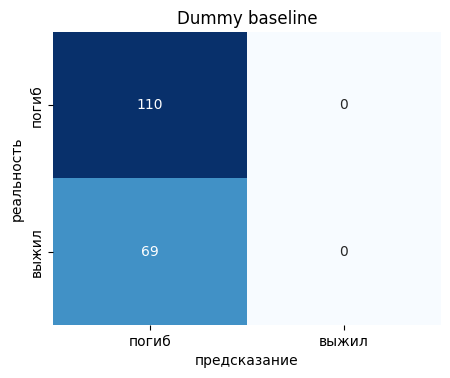

In [ ]:
plt.figure(figsize=(5, 3.8))
sns.heatmap(cm_dummy, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["погиб", "выжил"],
            yticklabels=["погиб", "выжил"])
plt.title("Dummy baseline")
plt.ylabel("реальность")
plt.xlabel("предсказание")
plt.show()

# Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_predict

In [ ]:
dt_big = DecisionTreeClassifier(random_state=42)
dt_big.fit(x_train, y_train)

acc_train_big = accuracy_score(y_train, dt_big.predict(x_train))
acc_test_big  = accuracy_score(y_test,  dt_big.predict(x_test))

tree_big_info = pd.DataFrame({
    "показатель": ["глубина дерева", "число листьев", "Accuracy train", "Accuracy test", "разрыв"],
    "значение": [dt_big.get_depth(), dt_big.get_n_leaves(),
                 acc_train_big, acc_test_big, acc_train_big - acc_test_big]
})
tree_big_info

,показатель,значение
0,глубина дерева,17.000000
1,число листьев,154.000000
2,Accuracy train,0.984551
3,Accuracy test,0.832402
4,разрыв,0.152148


In [ ]:
param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8],
    'min_samples_leaf': [3, 4, 5, 6, 8, 10],
    'criterion': ['gini', 'entropy'],
    'class_weight': ['balanced', None]
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid_dt.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'class_weight': ['balanced', None],
                         'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 4, 5, 6, 7, 8],
                         'min_samples_leaf': [3, 4, 5, 6, 8, 10]},
             scoring='f1')

In [ ]:
dt_best = grid_dt.best_estimator_

oof_proba_dt = cross_val_predict(
    dt_best, x_train, y_train,
    cv=5, method='predict_proba'
)[:, 1]

best_threshold_dt = 0.5

oof_preds = (oof_proba_dt >= best_threshold_dt).astype(int)
cv_f1_at_thresh = f1_score(y_train, oof_preds)

print(f"порог: {best_threshold_dt:.2f}")
print(f"F1 при этом пороге: {cv_f1_at_thresh:.4f}")


y_proba_dt = dt_best.predict(x_test)
y_pred_dt_best = (y_proba_dt >= best_threshold_dt).astype(int)

порог: 0.50
F1 при этом пороге: 0.7555


In [ ]:
acc_dt  = accuracy_score(y_test, y_pred_dt_best)
prec_dt = precision_score(y_test, y_pred_dt_best, zero_division=0)
rec_dt  = recall_score(y_test, y_pred_dt_best, zero_division=0)
f1_dt   = f1_score(y_test, y_pred_dt_best, zero_division=0)

metrics_dt = pd.DataFrame({
    "метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "Dummy":   [acc_dummy, prec_dummy, rec_dummy, f1_dummy],
    "Decision Tree": [acc_dt, prec_dt, rec_dt, f1_dt]
})

metrics_dt

,метрика,Dummy,Decision Tree
0,Accuracy,0.614525,0.810056
1,Precision,0.000000,0.753623
2,Recall,0.000000,0.753623
3,F1,0.000000,0.753623


In [ ]:
acc_test_dt = accuracy_score(y_test, y_pred_dt_best)

y_proba_dt_train = dt_best.predict_proba(X_train_scaled)[:, 1]
y_pred_dt_train = (y_proba_dt_train >= best_threshold_dt).astype(int)
acc_train_dt = accuracy_score(y_train, y_pred_dt_train)

print(f"Accuracy train: {acc_train_dt:.4f}")
print(f"Accuracy test:  {acc_test_dt:.4f}")
print(f"разрыв:         {acc_train_dt - acc_test_dt:.4f}")

Accuracy train: 0.7851
Accuracy test:  0.8101
разрыв:         -0.0249


In [ ]:
cm_dt = confusion_matrix(y_test, y_pred_dt_best)

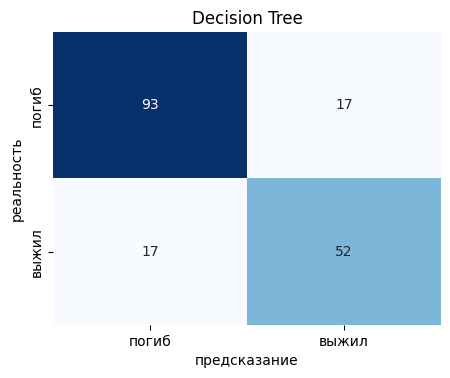

In [ ]:
plt.figure(figsize=(5, 3.8))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["погиб", "выжил"],
            yticklabels=["погиб", "выжил"])
plt.title("Decision Tree")
plt.ylabel("реальность")
plt.xlabel("предсказание")
plt.show()

In [ ]:
imp_dt = pd.DataFrame({
    "признак": X_train_scaled.columns,
    "важность": dt_best.feature_importances_
}).sort_values(by="важность", ascending=False).reset_index(drop=True)

imp_dt

,признак,важность
0,Title_Mr,0.451356
1,Fare,0.291641
2,Pclass,0.140263
3,Title_Rare,0.054890
4,Age,0.043285
5,Embarked_S,0.015344
6,SibSp,0.003221
7,Sex_male,0.000000
8,Sex_female,0.000000
9,Parch,0.000000


# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42)
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)

In [ ]:
acc_rf  = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf, zero_division=0)
rec_rf  = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf   = f1_score(y_test, y_pred_rf, zero_division=0)

metrics_rf = pd.DataFrame({
    "метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "Dummy":         [acc_dummy, prec_dummy, rec_dummy, f1_dummy],
    "Decision Tree": [acc_dt, prec_dt, rec_dt, f1_dt],
    "Random Forest": [acc_rf, prec_rf, rec_rf, f1_rf]
})
metrics_rf

,метрика,Dummy,Decision Tree,Random Forest
0,Accuracy,0.614525,0.810056,0.821229
1,Precision,0.000000,0.753623,0.793651
2,Recall,0.000000,0.753623,0.724638
3,F1,0.000000,0.753623,0.757576


In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

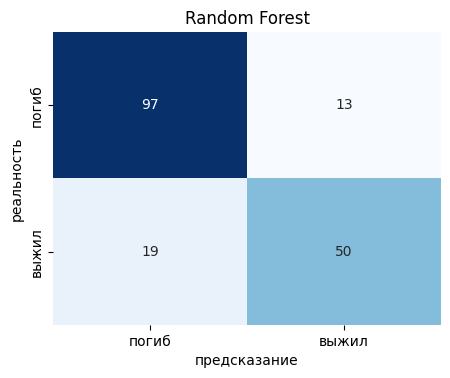

In [ ]:
plt.figure(figsize=(5, 3.8))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["погиб", "выжил"],
            yticklabels=["погиб", "выжил"])
plt.title("Random Forest")
plt.ylabel("реальность")
plt.xlabel("предсказание")
plt.show()

In [ ]:
acc_rf_train = accuracy_score(y_train, rf.predict(x_train))

gap_rf = pd.DataFrame({
    "выборка": ["train (712)", "OOB-проверка", "test (179)"],
    "Accuracy": [acc_rf_train, rf.oob_score_, acc_rf]
})
gap_rf

,выборка,Accuracy
0,train (712),0.984551
1,OOB-проверка,0.810393
2,test (179),0.821229


In [ ]:
imp_rf = pd.DataFrame({
    "признак": x_train.columns,
    "важность": rf.feature_importances_
}).sort_values(by="важность", ascending=False).reset_index(drop=True)

imp_rf

,признак,важность
0,Fare,0.242072
1,Age,0.219328
2,Title_Mr,0.107983
3,Sex_male,0.083705
4,Pclass,0.078478
5,Sex_female,0.078363
6,SibSp,0.053257
7,Parch,0.033736
8,Title_Mrs,0.028093
9,Title_Miss,0.024794


# Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
param_grid_gb = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5],
    'subsample': [0.8, 1.0]
}

grid_gb = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid_gb,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid_gb.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=GradientBoostingClassifier(random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 4, 5], 'n_estimators': [50, 100, 200],
                         'subsample': [0.8, 1.0]},
             scoring='f1')

In [ ]:
gb_best = grid_gb.best_estimator_
grid_gb.best_params_

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}

In [ ]:
y_pred_gb = gb_best.predict(x_test)

acc_gb  = accuracy_score(y_test, y_pred_gb)
prec_gb = precision_score(y_test, y_pred_gb, zero_division=0)
rec_gb  = recall_score(y_test, y_pred_gb, zero_division=0)
f1_gb   = f1_score(y_test, y_pred_gb, zero_division=0)

In [ ]:
metrics_gb = pd.DataFrame({
    "метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "Dummy":         [acc_dummy, prec_dummy, rec_dummy, f1_dummy],
    "Decision Tree": [acc_dt, prec_dt, rec_dt, f1_dt],
    "Random Forest": [acc_rf, prec_rf, rec_rf, f1_rf],
    "Gradient Boosting": [acc_gb, prec_gb, rec_gb, f1_gb]
})
metrics_gb

,метрика,Dummy,Decision Tree,Random Forest,Gradient Boosting
0,Accuracy,0.614525,0.810056,0.821229,0.826816
1,Precision,0.000000,0.753623,0.793651,0.816667
2,Recall,0.000000,0.753623,0.724638,0.710145
3,F1,0.000000,0.753623,0.757576,0.759690


In [ ]:
cm_gb = confusion_matrix(y_test, y_pred_gb)

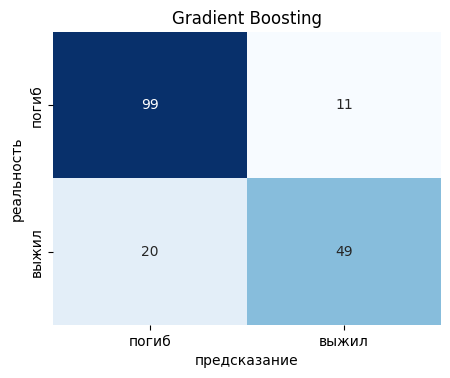

In [ ]:
plt.figure(figsize=(5, 3.8))
sns.heatmap(cm_gb, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["погиб", "выжил"],
            yticklabels=["погиб", "выжил"])
plt.title("Gradient Boosting")
plt.ylabel("реальность")
plt.xlabel("предсказание")
plt.show()

#Support Vector Machine

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_predict

In [ ]:
svm = SVC(kernel='rbf', C=1.0, class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)

SVC(class_weight='balanced', probability=True, random_state=42)

In [ ]:
oof_proba_svm = cross_val_predict(svm, X_train_scaled, y_train, cv=5, method='predict_proba')[:, 1]

In [ ]:
best_f1_svm = 0
best_thresh_svm = 0.5
for threshold in np.arange(0.20, 0.70, 0.01):
    preds = (oof_proba_svm >= threshold).astype(int)
    f1 = f1_score(y_train, preds)
    if f1 > best_f1_svm:
        best_f1_svm = f1
        best_thresh_svm = threshold

y_proba_svm = svm.predict_proba(X_test_scaled)[:, 1]
y_pred_svm = (y_proba_svm >= best_thresh_svm).astype(int)

In [ ]:
acc_svm  = accuracy_score(y_test, y_pred_svm)
prec_svm = precision_score(y_test, y_pred_svm, zero_division=0)
rec_svm  = recall_score(y_test, y_pred_svm, zero_division=0)
f1_svm   = f1_score(y_test, y_pred_svm, zero_division=0)

In [ ]:
metrics_svm = pd.DataFrame({
    "метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "Dummy":         [acc_dummy, prec_dummy, rec_dummy, f1_dummy],
    "Decision Tree": [acc_dt, prec_dt, rec_dt, f1_dt],
    "Random Forest": [acc_rf, prec_rf, rec_rf, f1_rf],
    "Gradient Boosting": [acc_gb, prec_gb, rec_gb, f1_gb],
    "SVM": [acc_svm, prec_svm, rec_svm, f1_svm]
})
metrics_svm

,метрика,Dummy,Decision Tree,Random Forest,Gradient Boosting,SVM
0,Accuracy,0.614525,0.810056,0.821229,0.826816,0.826816
1,Precision,0.000000,0.753623,0.793651,0.816667,0.806452
2,Recall,0.000000,0.753623,0.724638,0.710145,0.724638
3,F1,0.000000,0.753623,0.757576,0.759690,0.763359


In [ ]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

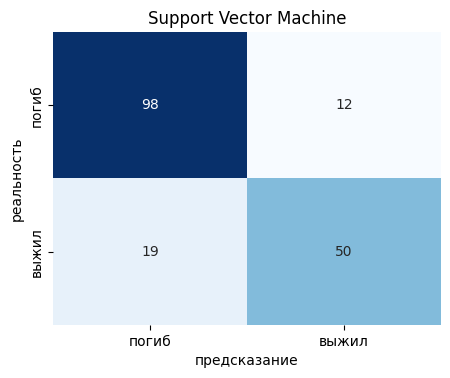

In [ ]:
plt.figure(figsize=(5, 3.8))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["погиб", "выжил"],
            yticklabels=["погиб", "выжил"])
plt.title("Support Vector Machine")
plt.ylabel("реальность")
plt.xlabel("предсказание")
plt.show()

# K-Nearest Neighbors

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier(weights='distance')

In [ ]:
oof_proba_knn = cross_val_predict(knn, X_train_scaled, y_train, cv=5, method='predict_proba')[:, 1]

In [ ]:
best_f1_knn = 0
best_thresh_knn = 0.5
for threshold in np.arange(0.20, 0.70, 0.01):
    preds = (oof_proba_knn >= threshold).astype(int)
    f1 = f1_score(y_train, preds)
    if f1 > best_f1_knn:
        best_f1_knn = f1
        best_thresh_knn = threshold

y_proba_knn = knn.predict_proba(X_test_scaled)[:, 1]
y_pred_knn = (y_proba_knn >= best_thresh_knn).astype(int)

In [ ]:
acc_knn  = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn, zero_division=0)
rec_knn  = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn   = f1_score(y_test, y_pred_knn, zero_division=0)

In [ ]:
metrics_knn = pd.DataFrame({
    "метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "Dummy":         [acc_dummy, prec_dummy, rec_dummy, f1_dummy],
    "Decision Tree": [acc_dt, prec_dt, rec_dt, f1_dt],
    "Random Forest": [acc_rf, prec_rf, rec_rf, f1_rf],
    "Gradient Boosting": [acc_gb, prec_gb, rec_gb, f1_gb],
    "SVM": [acc_svm, prec_svm, rec_svm, f1_svm],
    "KNN": [acc_knn, prec_knn, rec_knn, f1_knn]
})
metrics_knn

,метрика,Dummy,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
0,Accuracy,0.614525,0.810056,0.821229,0.826816,0.826816,0.804469
1,Precision,0.000000,0.753623,0.793651,0.816667,0.806452,0.765625
2,Recall,0.000000,0.753623,0.724638,0.710145,0.724638,0.710145
3,F1,0.000000,0.753623,0.757576,0.759690,0.763359,0.736842


In [ ]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

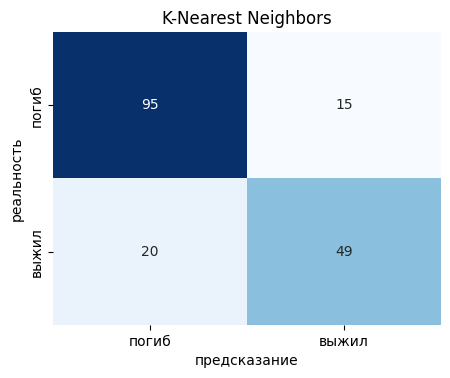

In [ ]:
plt.figure(figsize=(5, 3.8))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["погиб", "выжил"],
            yticklabels=["погиб", "выжил"])
plt.title("K-Nearest Neighbors")
plt.ylabel("реальность")
plt.xlabel("предсказание")
plt.show()

# честное сравнение моделей

In [ ]:
metrics_knn = pd.DataFrame({
    "метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "Dummy":         [acc_dummy, prec_dummy, rec_dummy, f1_dummy],
    "Decision Tree": [acc_dt, prec_dt, rec_dt, f1_dt],
    "Random Forest": [acc_rf, prec_rf, rec_rf, f1_rf],
    "Gradient Boosting": [acc_gb, prec_gb, rec_gb, f1_gb],
    "SVM": [acc_svm, prec_svm, rec_svm, f1_svm],
    "KNN": [acc_knn, prec_knn, rec_knn, f1_knn]
})
metrics_knn

,метрика,Dummy,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
0,Accuracy,0.614525,0.810056,0.821229,0.826816,0.826816,0.804469
1,Precision,0.000000,0.753623,0.793651,0.816667,0.806452,0.765625
2,Recall,0.000000,0.753623,0.724638,0.710145,0.724638,0.710145
3,F1,0.000000,0.753623,0.757576,0.759690,0.763359,0.736842


# Feature Importance

    признак  Decision Tree  Random Forest  Gradient Boosting
0      Fare       0.291641       0.242072           0.270027
1       Age       0.043285       0.219328           0.141589
2  Title_Mr       0.451356       0.107983           0.258277
3  Sex_male       0.000000       0.083705           0.021093
4    Pclass       0.140263       0.078478           0.108129


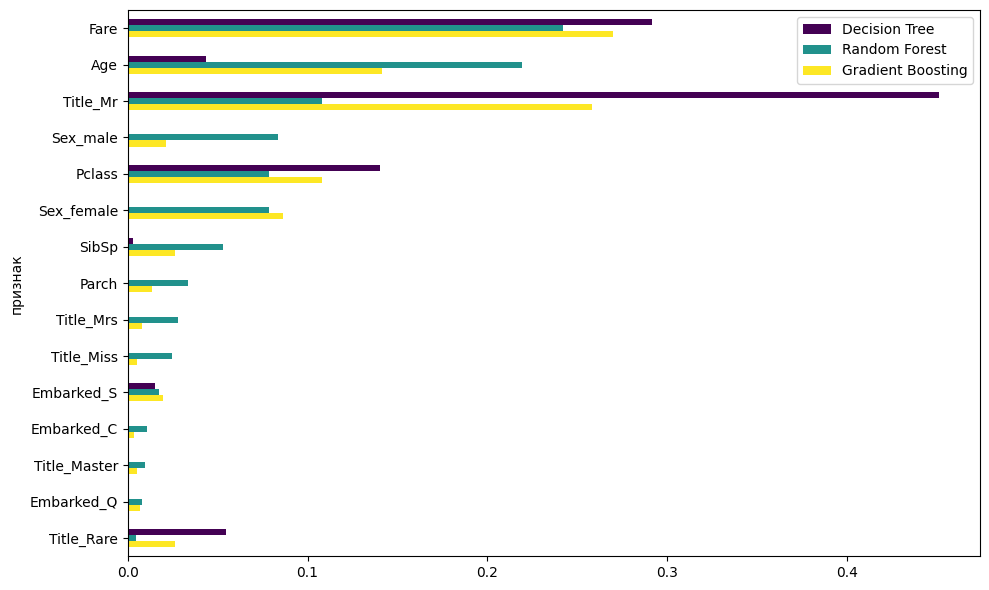

In [ ]:
imp_gb = pd.DataFrame({
    "признак": X_train_scaled.columns,
    "важность": gb_best.feature_importances_
}).sort_values(by="важность", ascending=False).reset_index(drop=True)

imp_comparison = pd.DataFrame({
    "признак": X_train_scaled.columns,
    "Decision Tree": dt_best.feature_importances_,
    "Random Forest": rf.feature_importances_,
    "Gradient Boosting": gb_best.feature_importances_
}).sort_values(by="Random Forest", ascending=False).reset_index(drop=True)

print(imp_comparison.head())

imp_comparison.set_index('признак').plot(kind='barh', figsize=(10, 6), colormap='viridis')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# анализ ошибок


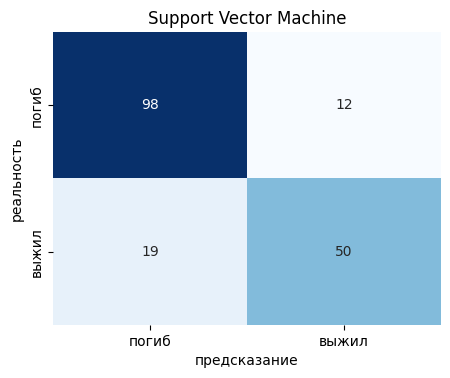

In [ ]:
plt.figure(figsize=(5, 3.8))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["погиб", "выжил"],
            yticklabels=["погиб", "выжил"])
plt.title("Support Vector Machine")
plt.ylabel("реальность")
plt.xlabel("предсказание")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

errors_df = X_test_scaled.copy()

errors_df = pd.DataFrame(scaler.inverse_transform(X_test_scaled), columns=X_test_scaled.columns, index=X_test_scaled.index)

errors_df['y_true'] = y_test
errors_df['y_pred'] = y_pred_svm

errors_only = errors_df[errors_df['y_true'] != errors_df['y_pred']]

print("\nFalse Negative")
fn_errors = errors_only[(errors_only['y_true'] == 1) & (errors_only['y_pred'] == 0)]
print(fn_errors[['Pclass', 'Age', 'Fare', 'Sex_female', 'Title_Mr', 'Title_Mrs', 'Title_Miss']].head(5))

print("\nFalse Positive")
fp_errors = errors_only[(errors_only['y_true'] == 0) & (errors_only['y_pred'] == 1)]
print(fp_errors[['Pclass', 'Age', 'Fare', 'Sex_female', 'Title_Mr', 'Title_Mrs', 'Title_Miss']].head(5))


False Negative
             Pclass        Age      Fare  Sex_female  Title_Mr  Title_Mrs  \
PassengerId                                                                 
554             3.0  22.000000  2.107178         0.0       1.0        0.0   
713             1.0  48.000000  3.970292         0.0       1.0        0.0   
456             3.0  29.000000  2.185579         0.0       1.0        0.0   
18              2.0  29.699118  2.639057         0.0       1.0        0.0   
680             1.0  36.000000  6.240917         0.0       1.0        0.0   

             Title_Miss  
PassengerId              
554                 0.0  
713                 0.0  
456                 0.0  
18                  0.0  
680                 0.0  

False Positive
             Pclass        Age      Fare  Sex_female  Title_Mr  Title_Mrs  \
PassengerId                                                                 
746             1.0  70.000000  4.276666         0.0       0.0        0.0   
298            